# Comparison of all the models and recommendation (Tâche 4)
The director's question: *the kiosks run on modest CPUs, the team is small and the budget is limited. Is a neural network worth it in production, or would a simpler classical model do the job?*

To answer, we put every model of the project in one table, with what it brings (test accuracy on the same 250 paintings) and what it costs on a kiosk:
- **CPU time per image**: one painting, the whole pipeline (preparing the image + the model), on **1 core** (a modest kiosk CPU), median of 50 runs;
- **size on disk**: what the kiosk has to store;
- **parameters**: total numbers in the model, and how many we trained ourselves.

Accuracies come from the notebooks of the team (`mlp.ipynb`, `resnet.ipynb`, `baseline.ipynb`). The CPU time does not depend on the trained weights, only on the architecture, so we rebuild each architecture here and time it (same method as `cpu_latency_ms` in `resnet.ipynb`).

**On Colab**: this notebook is run by the last cell of `baseline.ipynb`, in the same session, because it needs the models saved there (`models/` is not in Git). Locally: run `baseline.ipynb` once, then this notebook.
Note: on Colab the CPU is a server CPU, so the absolute times are only indicative; what matters is the **ratio between models**, measured on the same machine.

## Setup

In [1]:
import os
import sys
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
sys.path.insert(0, "src")

import json
import pickle
import platform

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18

from museum_guide.baseline import pixel_features, colour_histogram, load_frozen_resnet
from museum_guide.benchmark import count_parameters, cpu_latency_ms, torch_size_mb, sklearn_size_mb
from museum_guide.data import prepare_resnet
from museum_guide.mlp import make_tuned_mlp

torch.manual_seed(0)
N_TEST = 250
print("CPU:", platform.processor() or platform.machine(), "|", os.cpu_count(), "cores available, timing on 1")

CPU: x86_64 | 2 cores available, timing on 1


## 1. Accuracy of every model (same 250 test paintings)
The neural-network numbers are copied from the notebooks of the team (outputs committed in Git); the baselines are read from `reports/baseline_metrics.json`.

In [2]:
with open("reports/baseline_metrics.json") as f:
    base = json.load(f)

acc = {
    # model: (test accuracy, macro-F1, trained parameters, source)
    # the MLP is trained entirely, so trained parameters = all its parameters (filled in section 3); no macro-F1 in mlp.ipynb
    "MLP, 1 sigmoid layer":         (0.284, None, None, "mlp.ipynb, Part A"),
    "MLP, 3 ReLU layers":           (0.356, None, None, "mlp.ipynb, tuned (PR #4)"),
    "ResNet-18, head only":         (0.732, 0.734, 2_565, "resnet.ipynb, step A (PR #3)"),
    "ResNet-18, layer4 + head":     (0.776, 0.776, 8_396_293, "resnet.ipynb, step B (PR #3)"),
    "LogReg, colour histogram":     (base["logreg_colours"]["test_acc"], base["logreg_colours"]["test_macro_f1"],
                                     base["logreg_colours"]["parameters"], "baseline.ipynb"),
    "LogReg, pixels":               (base["logreg_pixels"]["test_acc"], base["logreg_pixels"]["test_macro_f1"],
                                     base["logreg_pixels"]["parameters"], "baseline.ipynb"),
    "LogReg, frozen ResNet features": (base["logreg_resnet"]["test_acc"], base["logreg_resnet"]["test_macro_f1"],
                                     base["logreg_resnet"]["parameters"], "baseline.ipynb"),
}

## 2. The pipeline of each model on a kiosk
Each function takes **one** image `(1, 3, 128, 128)` in [0, 1] and returns a style, exactly what the kiosk does for one visitor.

In [3]:
stats = json.load(open("splits/stats.json"))         # mean / std of the MLP input, written by data.py
logreg = {n: pickle.load(open(f"models/{n}.pkl", "rb")) for n in ["logreg_pixels", "logreg_colours", "logreg_resnet"]}

# MLP: resize to 64 px, standardise like prepare_mlp, then the network
mlp = make_tuned_mlp().eval()
mlp_a = nn.Sequential(nn.Flatten(), nn.Linear(3 * 64 * 64, 128), nn.Sigmoid(), nn.Linear(128, 5)).eval()   # Part A
def mlp_pipeline(net):
    def predict(img):
        x = F.interpolate(img, size=64, mode="bilinear", align_corners=False)
        return net((x - stats["mean"]) / stats["std"]).argmax(dim=1)
    return predict

# fine-tuned ResNet: same architecture for step A and step B (only the trained weights differ)
resnet = resnet18(weights=None)
resnet.fc = nn.Linear(512, 5)
resnet.eval()
def resnet_predict(img):
    return resnet(prepare_resnet(img)).argmax(dim=1)

# logistic regressions
backbone = load_frozen_resnet(pretrained=False)     # weights do not change the time, no download needed
def logreg_pixels(img):
    return logreg["logreg_pixels"].predict(pixel_features(img))
def logreg_colours(img):
    return logreg["logreg_colours"].predict(colour_histogram(img))
def logreg_resnet(img):
    return logreg["logreg_resnet"].predict(backbone(prepare_resnet(img)).numpy())

pipelines = {
    "MLP, 1 sigmoid layer": mlp_pipeline(mlp_a),
    "MLP, 3 ReLU layers": mlp_pipeline(mlp),
    "ResNet-18, head only": resnet_predict,       # step B has the same architecture, timed once (see below)
    "LogReg, colour histogram": logreg_colours,
    "LogReg, pixels": logreg_pixels,
    "LogReg, frozen ResNet features": logreg_resnet,
}
test_img = torch.rand(1, 3, 128, 128)
for name, f in pipelines.items():                    # quick check that every pipeline runs
    assert int(f(test_img)[0]) in range(5), name
print("all pipelines run")

all pipelines run


## 3. CPU time and size

In [4]:
size = {
    "MLP, 1 sigmoid layer": torch_size_mb(mlp_a, "models/mlp_a_arch.pt"),
    "MLP, 3 ReLU layers": torch_size_mb(mlp, "models/mlp_arch.pt"),
    "ResNet-18, head only": torch_size_mb(resnet, "models/resnet_arch.pt"),
    "LogReg, colour histogram": base["logreg_colours"]["size_mb"],
    "LogReg, pixels": base["logreg_pixels"]["size_mb"],
    "LogReg, frozen ResNet features": torch_size_mb(backbone, "models/backbone_arch.pt") + base["logreg_resnet"]["size_mb"],
}
size["ResNet-18, layer4 + head"] = size["ResNet-18, head only"]
n_params = {
    "MLP, 1 sigmoid layer": count_parameters(mlp_a), "MLP, 3 ReLU layers": count_parameters(mlp),
    "ResNet-18, head only": count_parameters(resnet), "ResNet-18, layer4 + head": count_parameters(resnet),
    "LogReg, colour histogram": base["logreg_colours"]["parameters"], "LogReg, pixels": base["logreg_pixels"]["parameters"],
    "LogReg, frozen ResNet features": count_parameters(backbone) + base["logreg_resnet"]["parameters"],
}
latency = {}
for name, f in pipelines.items():
    latency[name] = cpu_latency_ms(f)
    print(f"{name:32s} {latency[name]:7.2f} ms per image (1 core)")
latency["ResNet-18, layer4 + head"] = latency["ResNet-18, head only"]   # same network, only the weights differ

MLP, 1 sigmoid layer                0.78 ms per image (1 core)


MLP, 3 ReLU layers                  1.05 ms per image (1 core)


ResNet-18, head only               24.31 ms per image (1 core)
LogReg, colour histogram            0.94 ms per image (1 core)
LogReg, pixels                      0.77 ms per image (1 core)


LogReg, frozen ResNet features     25.45 ms per image (1 core)


In [5]:
rows = []
for name, (a, f1, trained, source) in acc.items():
    if trained is None:
        trained = n_params[name]
    rows.append({"model": name, "test accuracy": a, "± 1 std": np.sqrt(a * (1 - a) / N_TEST), "macro-F1": f1,
                 "CPU ms / image (1 core)": latency[name], "size MB": size[name], "parameters": n_params[name],
                 "trained parameters": trained, "source": source})
results = pd.DataFrame(rows).sort_values("test accuracy").reset_index(drop=True)
display(results.style.format({"test accuracy": "{:.3f}", "± 1 std": "{:.3f}", "macro-F1": "{:.3f}",
                              "CPU ms / image (1 core)": "{:.2f}", "size MB": "{:.1f}",
                              "parameters": "{:,.0f}", "trained parameters": "{:,.0f}"}, na_rep="-").hide(axis="index"))
os.makedirs("reports", exist_ok=True)
results.to_csv("reports/comparison.csv", index=False)

model,test accuracy,± 1 std,macro-F1,CPU ms / image (1 core),size MB,parameters,trained parameters,source
"MLP, 1 sigmoid layer",0.284,0.029,-,0.78,6.3,"1,573,637","1,573,637","mlp.ipynb, Part A"
"MLP, 3 ReLU layers",0.356,0.030,-,1.05,12.8,"3,187,461","3,187,461","mlp.ipynb, tuned (PR #4)"
"LogReg, pixels",0.356,0.030,0.341,0.77,0.8,"61,445","61,445",baseline.ipynb
"LogReg, colour histogram",0.428,0.031,0.429,0.94,0.0,"2,565","2,565",baseline.ipynb
"LogReg, frozen ResNet features",0.728,0.028,0.730,25.45,44.8,"11,179,077","2,565",baseline.ipynb
"ResNet-18, head only",0.732,0.028,0.734,24.31,44.8,"11,179,077","2,565","resnet.ipynb, step A (PR #3)"
"ResNet-18, layer4 + head",0.776,0.026,0.776,24.31,44.8,"11,179,077","8,396,293","resnet.ipynb, step B (PR #3)"


## 4. What each model brings vs what it costs
Each point is a model: higher = more accurate, more to the right = slower on the kiosk. The vertical bars are ± 1 standard deviation (about 3 points with 250 test paintings).

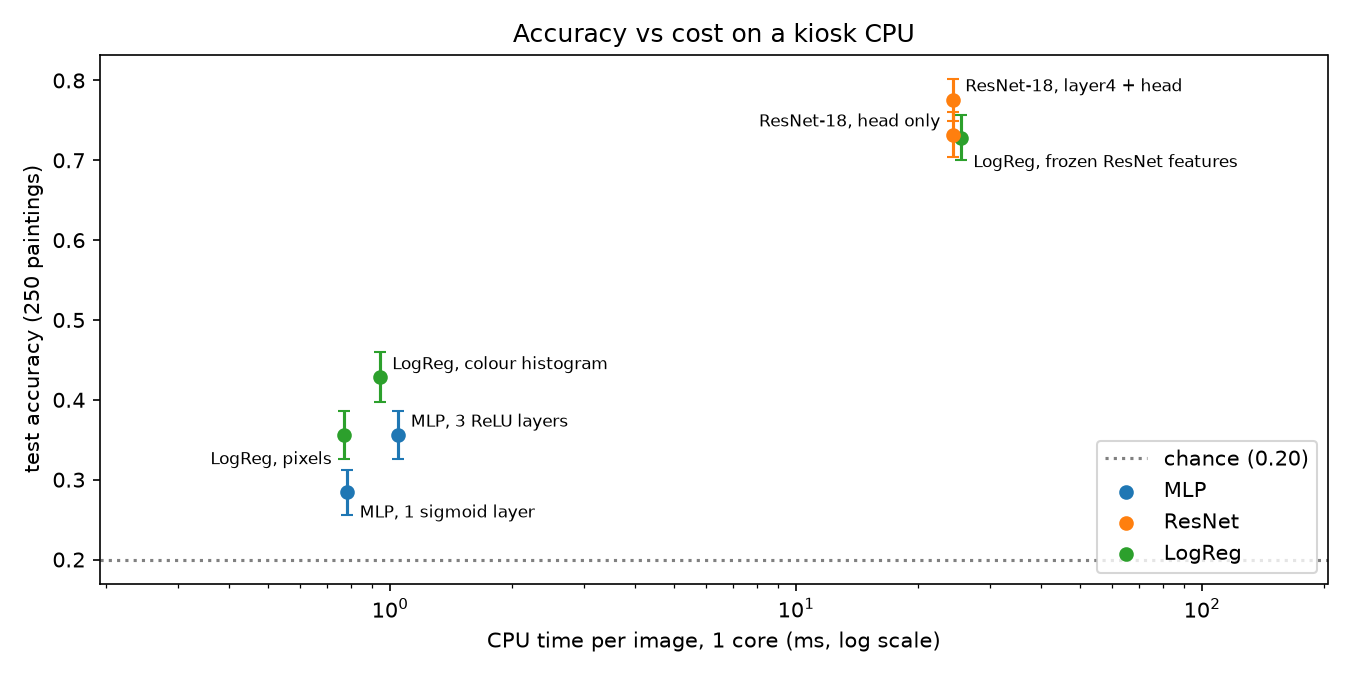

In [6]:
colour = {"MLP": "tab:blue", "ResNet": "tab:orange", "LogReg": "tab:green"}
# where to write each label (offset in points, alignment): some models have almost the same time and accuracy
LABEL_POS = {
    "MLP, 1 sigmoid layer": (6, -12, "left"),
    "MLP, 3 ReLU layers": (6, 4, "left"),
    "LogReg, pixels": (-6, -14, "right"),
    "LogReg, colour histogram": (6, 4, "left"),
    "LogReg, frozen ResNet features": (6, -14, "left"),
    "ResNet-18, head only": (-6, 4, "right"),
    "ResNet-18, layer4 + head": (6, 4, "left"),
}
plt.figure(figsize=(9, 4.5))
for _, r in results.iterrows():
    c = colour[r["model"].split("-")[0].split(",")[0]]
    plt.errorbar(r["CPU ms / image (1 core)"], r["test accuracy"], yerr=r["± 1 std"], fmt="o", color=c, capsize=3)
    dx, dy, ha = LABEL_POS[r["model"]]
    plt.annotate(r["model"], (r["CPU ms / image (1 core)"], r["test accuracy"]), textcoords="offset points",
                 xytext=(dx, dy), ha=ha, fontsize=8)
plt.axhline(0.20, color="grey", linestyle=":", label="chance (0.20)")
plt.xscale("log"); plt.xlim(results["CPU ms / image (1 core)"].min() / 4, results["CPU ms / image (1 core)"].max() * 8)
plt.xlabel("CPU time per image, 1 core (ms, log scale)"); plt.ylabel("test accuracy (250 paintings)")
for k, c in colour.items():
    plt.scatter([], [], color=c, label=k)
plt.legend(loc="lower right"); plt.title("Accuracy vs cost on a kiosk CPU")
plt.tight_layout(); plt.savefig("reports/accuracy_vs_cpu.png", dpi=150); plt.show()

## 5. Recommendation for the director
The cell prints the facts the recommendation is built on. The written recommendation is below it.

In [7]:
get = lambda n: results.set_index("model").loc[n]
best_classic = results[results["model"].str.startswith("LogReg, p") | results["model"].str.startswith("LogReg, c")] \
    .sort_values("test accuracy").iloc[-1]
mlp_r, ft, head, lr_res = get("MLP, 3 ReLU layers"), get("ResNet-18, layer4 + head"), get("ResNet-18, head only"), \
    get("LogReg, frozen ResNet features")
print(f'''- Best model without any network: {best_classic["model"]}, {best_classic["test accuracy"]:.3f}, {best_classic["CPU ms / image (1 core)"]:.2f} ms.
- MLP: {mlp_r["test accuracy"]:.3f}, {mlp_r["CPU ms / image (1 core)"]:.2f} ms -> {(mlp_r["test accuracy"] - best_classic["test accuracy"]) * 100:+.1f} points vs the best classical model.
- Frozen ResNet + logistic regression: {lr_res["test accuracy"]:.3f}, {lr_res["CPU ms / image (1 core)"]:.1f} ms, {lr_res["size MB"]:.0f} MB.
- Fine-tuned ResNet (layer4 + head): {ft["test accuracy"]:.3f}, {ft["CPU ms / image (1 core)"]:.1f} ms, {ft["size MB"]:.0f} MB
  -> {(ft["test accuracy"] - best_classic["test accuracy"]) * 100:+.1f} points vs the best classical model, for {ft["CPU ms / image (1 core)"] / best_classic["CPU ms / image (1 core)"]:.0f}x the CPU time.
- Fine-tuning vs head only: {(ft["test accuracy"] - head["test accuracy"]) * 100:+.1f} points (1 std is about 3 points).''')

- Best model without any network: LogReg, colour histogram, 0.428, 0.94 ms.
- MLP: 0.356, 1.05 ms -> -7.2 points vs the best classical model.
- Frozen ResNet + logistic regression: 0.728, 25.5 ms, 45 MB.
- Fine-tuned ResNet (layer4 + head): 0.776, 24.3 ms, 45 MB
  -> +34.8 points vs the best classical model, for 26x the CPU time.
- Fine-tuning vs head only: +4.4 points (1 std is about 3 points).


### Recommendation
**Yes, a neural network is worth it, but not the one built from scratch: a pretrained ResNet-18 (transfer learning).**

- **The MLP brings nothing.** On the same 64 x 64 pixels it gets 0.356, exactly like a logistic regression (0.356), and a colour histogram with no network at all does better (0.428). For the MLP, the simpler classical model really does the job, so we would not put the MLP on the kiosks.
- **ResNet brings +30 points** over the best model without a network (0.732 head only, 0.776 fine-tuned, vs 0.428). On our 5 styles, it is the difference between a guide that is wrong more than half of the time and a guide that is right about 3 times out of 4.
- **Cost on the kiosk:** about 25 ms per painting on 1 CPU core and 45 MB on disk. It is about 26 times slower than the colour histogram, but 25 ms is far below what a visitor notices after taking a photo, so a modest CPU is enough. No GPU is needed in production, only for training.
- **Cost for a small team:** step A only trains 2,565 parameters, and a logistic regression on the frozen features gives the same result (0.728 vs 0.732): it retrains in seconds when the collection changes. Fine-tuning `layer4` adds +4.4 points, less than two standard deviations with 250 test paintings, so the gain is likely but not certain, for the same cost on the kiosk.

**What we recommend:** the fine-tuned ResNet-18 (layer4 + head) on the kiosks, with the confidence guardrail of `resnet.ipynb` (τ = 0.7: on the validation set the guide answers 85% of the paintings and is right 84% of the time when it answers). If the team cannot maintain the fine-tuning, the head-only version is an almost equivalent fallback that is much easier to retrain.

**Limits:** only 250 test paintings (±3 points), 5 styles that are quite different from each other, CPU times measured on a Colab server CPU (the ratios between models matter more than the absolute times), and no test on real photos taken in the galleries (reflections, angles, lighting).